In [11]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

In [13]:
IMG_SIZE = 256
BATCH_SIZE = 32
EPOCH = 30
CHANNELS = 3

In [15]:
dataSet = tf.keras.preprocessing.image_dataset_from_directory(
    "PlantVillage",
    shuffle=True,
    image_size = (IMG_SIZE,IMG_SIZE),
    batch_size = BATCH_SIZE
    
)

Found 2152 files belonging to 3 classes.


In [17]:
class_names = dataSet.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

2026-10-07 19:51:07.446667: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


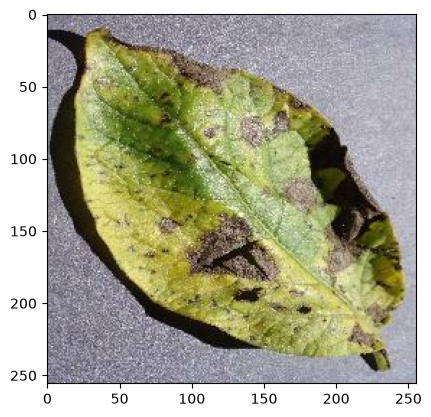

In [19]:
for image_batch, label_batch in dataSet.take(1):
    plt.imshow(image_batch[0].numpy().astype("uint8"))

In [21]:
len(dataSet)### Dataset has 68 elements and each elements has 32 imgs and thats the batch num

68

In [23]:

### Partitioning the data set (80%===> trainingSet & 20% for (10% ===> validation and the other 10% for testing))
def getDatasetPartitions(ds, train_split = 0.8, test_split = 0.1 , val_split = 0.1, shuffle=True, shuffle_size = 10000):
    
        ds_size = len(ds)

        if shuffle:
            ds = ds.shuffle(shuffle_size, seed=12)
        
        train_size = int(ds_size * train_split)
        val_size = int(val_split * ds_size)
    
        train_ds = ds.take(train_size)
        val_ds = ds.skip(train_size).take(val_size)
        test_ds = ds.skip(train_size).skip(val_size)
        
    
        return train_ds, test_ds, val_ds
    

In [25]:
train_ds, test_ds, val_ds = getDatasetPartitions(dataSet)

In [27]:
len(train_ds)

54

In [29]:
len(test_ds)

8

In [31]:
len(val_ds)

6

In [33]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE) 
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE) 

In [35]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMG_SIZE, IMG_SIZE),
    layers.Rescaling(1.0 / 255)
])

In [37]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2)
])

In [39]:
n_classes = 3

input_shape = (IMG_SIZE, IMG_SIZE, CHANNELS)

model = models.Sequential([
    
    layers.Input(shape=input_shape),
    
    resize_and_rescale,
    data_augmentation,

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])

In [41]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [45]:
history = model.fit(
    train_ds,
    epochs=EPOCH,
    batch_size=BATCH_SIZE,
    verbose=1,
    validation_data=val_ds
)

Epoch 1/30


/opt/anaconda3/envs/potato/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


54/54 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.5087 - loss: 0.9025 - val_accuracy: 0.4531 - val_loss: 0.8849
Epoch 2/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - accuracy: 0.6244 - loss: 0.7503 - val_accuracy: 0.7760 - val_loss: 0.4788
Epoch 3/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - accuracy: 0.8293 - loss: 0.3937 - val_accuracy: 0.8906 - val_loss: 0.2534
Epoch 4/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.8443 - loss: 0.3924 - val_accuracy: 0.8229 - val_loss: 0.4079
Epoch 5/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.8929 - loss: 0.2959 - val_accuracy: 0.9167 - val_loss: 0.2386
Epoch 6/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.8970 - loss: 0.2741 - val_accuracy: 0.8802 - val_loss: 0.3088
Epoch 7/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.8953 - loss: 0.2639 - val_accuracy: 0.8802 - val_loss: 0.2105
Epoch 8/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.9068 - loss: 0.2304 - val_accuracy: 0.8698 - val_loss: 0.3090
Epo

In [47]:
model.save("potato_disease_model.keras")

In [49]:
scores = model.evaluate(test_ds)

8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 320ms/step - accuracy: 0.9922 - loss: 0.0291


In [51]:
scores

[0.029120128601789474, 0.9921875]

In [53]:
history

In [55]:
history.params

{'verbose': 1, 'epochs': 30, 'steps': 54}

In [57]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [63]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss =history.history['loss']
val_loss =history.history['val_loss']

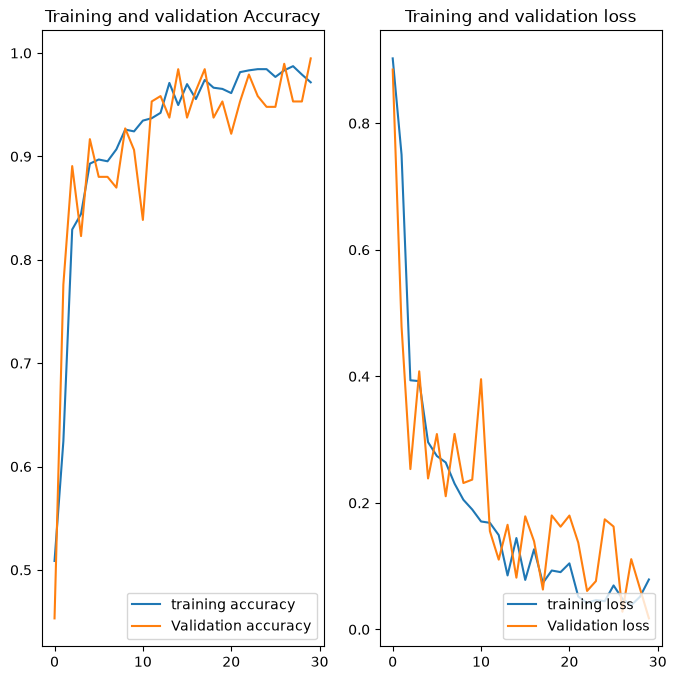

In [65]:
plt.figure(figsize=(8, 8))
plt.subplot(1,2,1)
plt.plot(range(EPOCH), acc, label='training accuracy')
plt.plot(range(EPOCH), val_acc, label='Validation accuracy')
plt.legend(loc='lower right')
plt.title('Training and validation Accuracy')

plt.subplot(1,2,2)
plt.plot(range(EPOCH), loss, label='training loss')
plt.plot(range(EPOCH), val_loss, label='Validation loss')
plt.legend(loc='lower right')
plt.title('Training and validation loss')
plt.show()

first image to predict
actual label :  Potato___Early_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 567ms/step
predicted label :  Potato___Early_blight


2026-10-07 20:36:17.652410: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


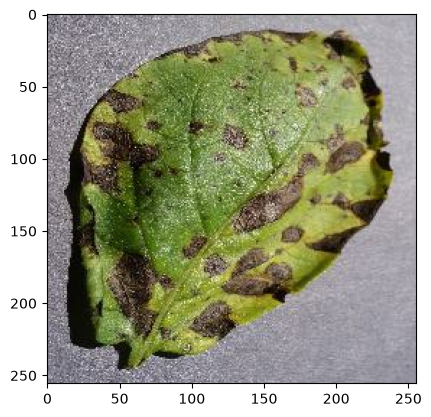

In [67]:
import numpy as np

for image_batch, label_batch in test_ds.take(1): ### we take 1 batch
    first_image = image_batch[0].numpy().astype('uint8') ### first image of the batch
    first_label = label_batch[0].numpy()

    print('first image to predict')
    plt.imshow(first_image)
    print("actual label : ", class_names[first_label])

    batch_predictions = model.predict(image_batch)
    print("predicted label : ",class_names[np.argmax(batch_predictions[0])])

In [69]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array, verbose=0)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * np.max(predictions[0]), 2)

    return predicted_class, confidence

2026-10-07 20:36:32.282594: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


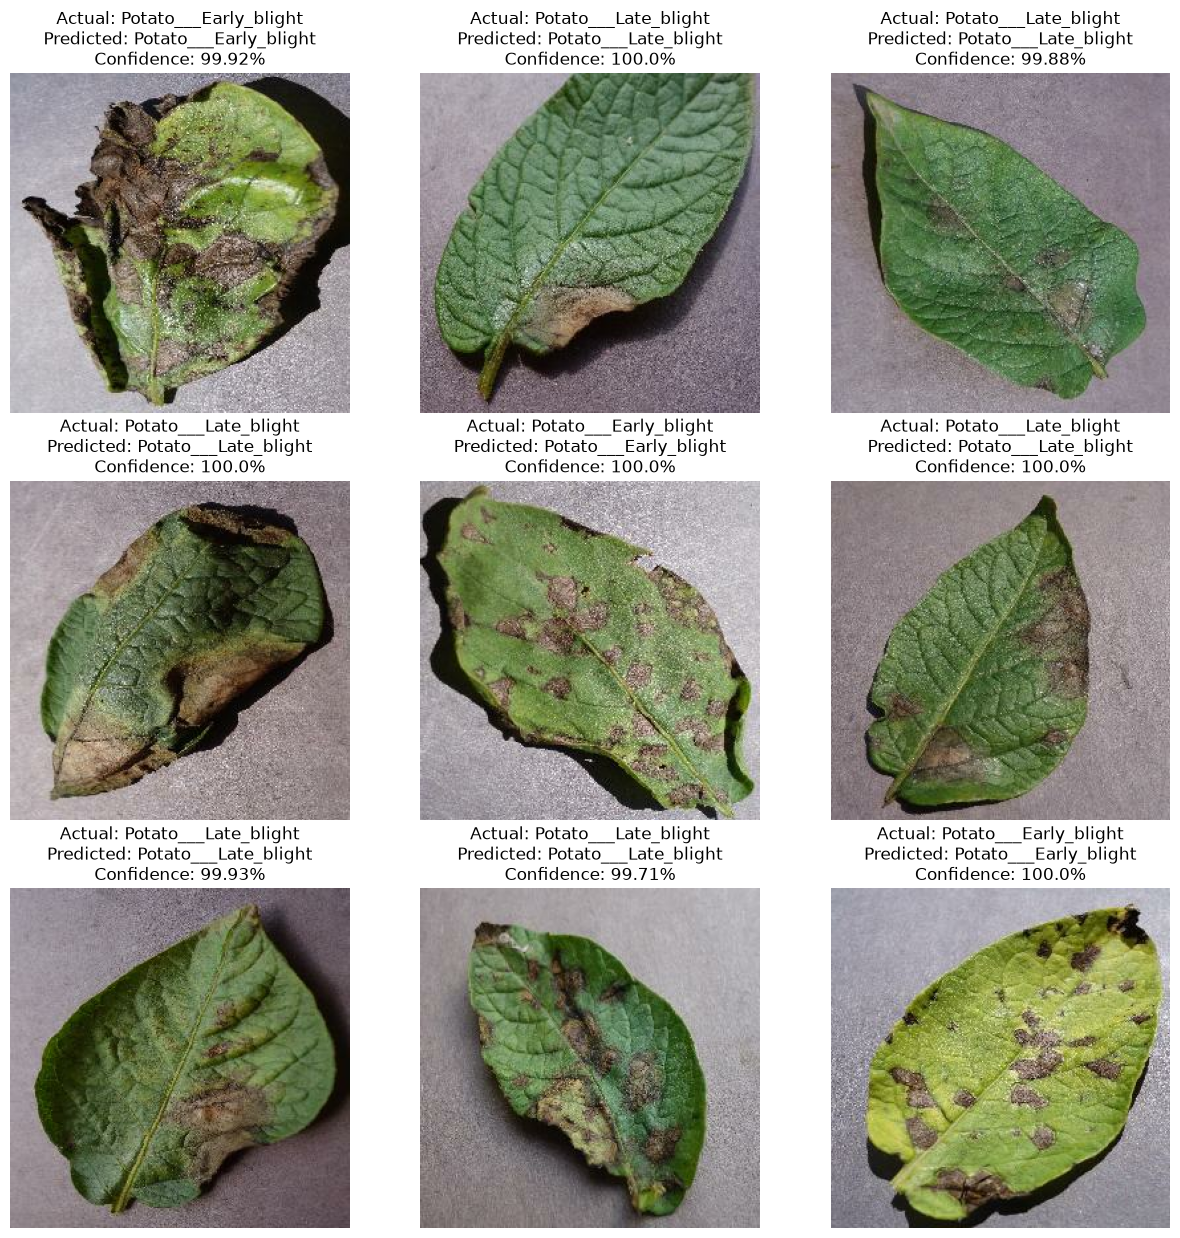

In [71]:
plt.figure(figsize=(15, 15))

for images, labels in test_ds.take(1):
    for i in range(9):

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        predicted_class, confidence = predict(model, images[i].numpy())

        actual_class = class_names[labels[i]]

        plt.title(
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence}%"
        )

        plt.axis("off")

In [85]:
import os

models_dir = "../models"
os.makedirs(models_dir, exist_ok=True)

# Détecter les dossiers numériques existants (ex: 1, 2, 3...)
existing_versions = [
    int(f) for f in os.listdir(models_dir) 
    if os.path.isdir(os.path.join(models_dir, f)) and f.isdigit()
]

# Calculer la version suivante
model_version = max(existing_versions + [0]) + 1

# Exportation au format SavedModel pour TF Serving
model.export(f"{models_dir}/{model_version}")

INFO:tensorflow:Assets written to: ../models/1/assets


INFO:tensorflow:Assets written to: ../models/1/assets


Saved artifact at '../models/1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  5351959616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5351959088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5351961200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5351964192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5351964016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5351963136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5351963664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5351963840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5350605216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5350606096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5350605920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5350

In [89]:
model.save("../models/potatoes1.keras")